# Vision — Statistik Dataset Gambar + Cari Gambar Kembar (deduplikasi hash)
**Kapan dipakai:** awal lomba, sebelum melatih apa pun. Menjawab: ukuran gambar seragam atau
tidak, kelas seimbang atau tidak, kelas mana yang gelap/berwarna aneh, dan **ada gambar kembar
antara train dan test?** (kebocoran: skor validasi terlalu bagus, skor leaderboard jelek).

**Langkah:** baca tiap gambar → ukuran, rasio, kecerahan, warna rata-rata → ringkasan per
kelas. Lalu `imagehash` phash → gambar dengan hash hampir sama = kembar / hampir kembar.

**Data demo:** CIFAR-10 kecil. Beberapa gambar test sengaja disisipkan (diedit) ke train.

In [1]:
import os

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
LABEL_COL = "label"
MAX_HAMMING = 6       # jarak hash <= angka ini dianggap kembar (0 = sama persis, maks 64)
N_INSERTED = 10       # HANYA DEMO: jumlah kembar buatan

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (4000, 2) | test: (1000, 2)


,path,label
0,train/airplane/0000.png,airplane
1,train/airplane/0001.png,airplane
2,train/airplane/0002.png,airplane
3,train/airplane/0003.png,airplane
4,train/airplane/0004.png,airplane


## Ukur tiap gambar
Satu baris per gambar: ukuran, rasio lebar/tinggi, kecerahan (0–255), rata-rata R G B, hash.

In [4]:
train["source"] = "train"
test["source"] = "test"
test[LABEL_COL] = ""      # test tidak berlabel
all_images = pd.concat([train, test], ignore_index=True)

rows = []
for path in all_images[PATH_COL]:
    file = f"{DATA_FOLDER}/{path}"
    image = Image.open(file).convert("RGB")
    pixels = np.asarray(image, dtype=float)
    rows.append({
        "width": image.width,
        "height": image.height,
        "ratio": image.width / image.height,
        "file_kb": os.path.getsize(file) / 1024,
        "brightness": pixels.mean(),
        "R": pixels[:, :, 0].mean(),
        "G": pixels[:, :, 1].mean(),
        "B": pixels[:, :, 2].mean(),
        "phash": str(imagehash.phash(image)),
    })
all_images = pd.concat([all_images, pd.DataFrame(rows)], axis=1)

train_stats = all_images[all_images["source"] == "train"].reset_index(drop=True)
test_stats = all_images[all_images["source"] == "test"].reset_index(drop=True)
print(train_stats[["width", "height", "ratio", "brightness"]].describe().round(2))

        width  height   ratio  brightness
count  4000.0  4000.0  4000.0     4000.00
mean     32.0    32.0     1.0      120.95
std       0.0     0.0     0.0       32.14
min      32.0    32.0     1.0       21.42
25%      32.0    32.0     1.0       99.99
50%      32.0    32.0     1.0      118.85
75%      32.0    32.0     1.0      139.65
max      32.0    32.0     1.0      252.14


## Ringkasan: ukuran, jumlah per kelas, warna rata-rata per kelas

ukuran unik (lebar, tinggi):
width  height
32     32        4000
dtype: int64
            brightness      R      G      B  count
label                                             
airplane         143.9  134.6  144.1  152.9    400
automobile       115.8  119.8  115.0  112.6    400
bird             119.8  124.2  126.0  109.1    400
cat              114.0  123.6  114.3  104.2    400
deer             113.9  123.0  119.9   98.7    400
dog              118.4  128.0  119.0  108.1    400
frog             106.6  120.2  112.2   87.5    400
horse            120.4  128.8  123.6  108.8    400
ship             134.2  125.4  134.8  142.3    400
truck            122.5  125.5  122.3  119.8    400


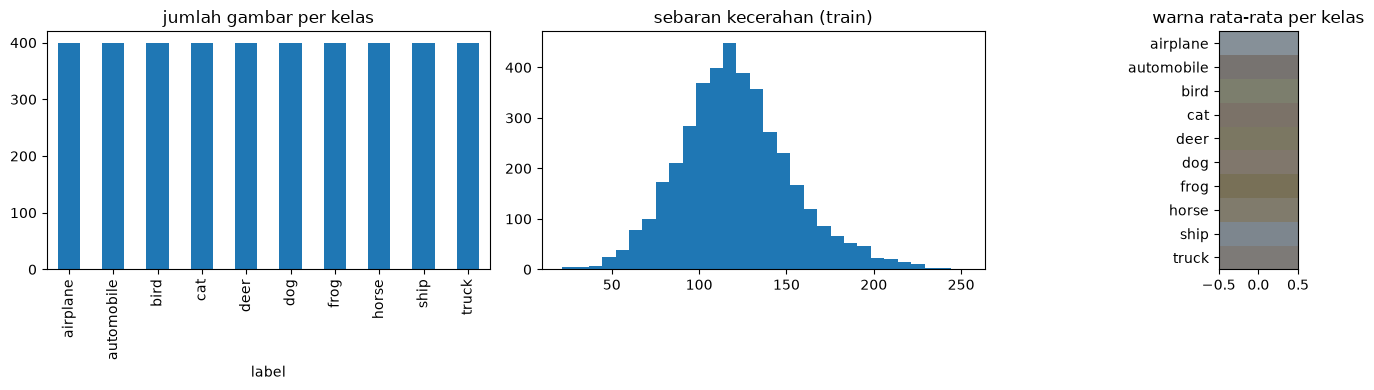

In [5]:
print("ukuran unik (lebar, tinggi):")
print(train_stats.groupby(["width", "height"]).size())

summary = train_stats.groupby(LABEL_COL)[["brightness", "R", "G", "B"]].mean()
summary = summary.round(1)
summary["count"] = train_stats[LABEL_COL].value_counts()
print(summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
summary["count"].plot.bar(ax=axes[0], title="jumlah gambar per kelas")
axes[1].hist(train_stats["brightness"], bins=30)
axes[1].set_title("sebaran kecerahan (train)")
colors = summary[["R", "G", "B"]].to_numpy() / 255
axes[2].imshow(colors.reshape(len(summary), 1, 3), aspect=0.3)
axes[2].set_yticks(range(len(summary)), list(summary.index))
axes[2].set_title("warna rata-rata per kelas")
plt.tight_layout()
plt.savefig("statistik.png", dpi=110)
plt.show()

## Sisipkan kembar buatan (HANYA DEMO, hapus sel ini saat lomba)
Ambil beberapa gambar test, edit sedikit (lebih terang, diperkecil), taruh di tabel train.
Gambar editan disimpan di folder notebook supaya bisa digambar nanti.

In [6]:
inserted = []
for number in range(N_INSERTED):
    original = Image.open(f"{DATA_FOLDER}/{test[PATH_COL][number * 90]}").convert("RGB")
    edited = ImageEnhance.Brightness(original).enhance(1.2)
    edited = edited.resize((24, 24))
    file_name = f"SISIPAN_{number}.png"
    edited.save(file_name)
    inserted.append({
        PATH_COL: file_name,
        "source": "train",
        "phash": str(imagehash.phash(edited)),
        LABEL_COL: "sisipan",
    })
train_stats = pd.concat([train_stats, pd.DataFrame(inserted)], ignore_index=True)
print(train_stats.shape)

(4010, 13)


## Cari kembar train ↔ test
Hash teks diubah jadi 64 bit. Jarak Hamming = jumlah bit berbeda. Tiap gambar test dibandingkan
dengan semua gambar train. Kembar sama persis saja:
`train_stats["phash"].isin(test_stats["phash"]).sum()`.

In [7]:
train_bits = []
for text in train_stats["phash"]:
    train_bits.append(imagehash.hex_to_hash(text).hash.flatten())
train_bits = np.array(train_bits)

twins = []
for row in range(len(test_stats)):
    test_bits = imagehash.hex_to_hash(test_stats["phash"][row]).hash.flatten()
    distances = (train_bits != test_bits).sum(axis=1)       # jarak ke semua gambar train
    nearest = distances.argmin()
    if distances[nearest] <= MAX_HAMMING:
        twins.append({
            "test": test_stats[PATH_COL][row],
            "train": train_stats[PATH_COL][nearest],
            "distance": distances[nearest],
            "train_label": train_stats[LABEL_COL][nearest],
        })
twins = pd.DataFrame(twins)
print("gambar test yang punya kembar di train:", len(twins), "dari", len(test_stats))
print(twins.sort_values("distance").head(15))
twins.to_csv("kembar_train_test.csv", index=False)

gambar test yang punya kembar di train: 11 dari 1000
                        test                      train  distance train_label
1     test/airplane/0090.png              SISIPAN_1.png         0     sisipan
4         test/bird/0070.png              SISIPAN_3.png         0     sisipan
10        test/ship/0010.png              SISIPAN_9.png         0     sisipan
9        test/horse/0020.png              SISIPAN_8.png         0     sisipan
6         test/deer/0050.png              SISIPAN_5.png         2     sisipan
7          test/dog/0040.png              SISIPAN_6.png         2     sisipan
5          test/cat/0060.png              SISIPAN_4.png         2     sisipan
3   test/automobile/0080.png              SISIPAN_2.png         2     sisipan
8         test/frog/0030.png              SISIPAN_7.png         2     sisipan
2   test/automobile/0072.png  train/automobile/0069.png         4  automobile
0     test/airplane/0000.png              SISIPAN_0.png         6     sisipan


## Kembar di dalam train, dan kembar yang labelnya beda (label berisik?)

In [8]:
doubles = train_stats[train_stats.duplicated("phash", keep=False)]
print("gambar train dengan phash persis sama dengan gambar train lain:", len(doubles))
label_variety = doubles.groupby("phash")[LABEL_COL].nunique()
print("grup hash dengan label berbeda:", (label_variety > 1).sum())
print(doubles.sort_values("phash")[[PATH_COL, LABEL_COL, "phash"]].head(10))

gambar train dengan phash persis sama dengan gambar train lain: 0
grup hash dengan label berbeda: 0
Empty DataFrame
Columns: [path, label, phash]
Index: []


## Contoh pasangan kembar (atas: test, bawah: train)

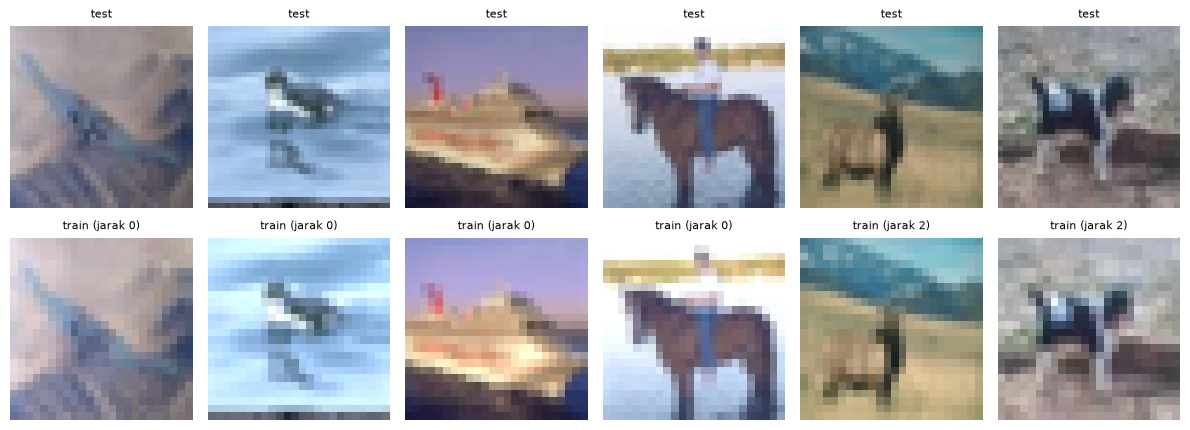

In [9]:
examples = twins.sort_values("distance").head(6)
examples = examples.reset_index(drop=True)
fig, axes = plt.subplots(2, len(examples), figsize=(2 * len(examples), 4.5), squeeze=False)
for column in range(len(examples)):
    axes[0, column].imshow(Image.open(f"{DATA_FOLDER}/{examples['test'][column]}"))
    axes[0, column].set_title("test", fontsize=8)
    train_path = examples["train"][column]
    if train_path.startswith("SISIPAN"):
        axes[1, column].imshow(Image.open(train_path))      # gambar editan di folder notebook
    else:
        axes[1, column].imshow(Image.open(f"{DATA_FOLDER}/{train_path}"))
    axes[1, column].set_title(f"train (jarak {examples['distance'][column]})", fontsize=8)
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.savefig("kembar_contoh.png", dpi=110)
plt.show()

## Simpan tabel ukuran semua gambar (untuk notebook lain / laporan)

In [10]:
all_stats = pd.concat([train_stats, test_stats], ignore_index=True)
all_stats.to_csv("ukuran_semua_gambar.csv", index=False)
print(all_stats.shape)

(5010, 13)
